In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
customer = pd.read_csv('customer_data.csv')

In [ ]:
customer

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29
...,...,...,...,...,...,...,...
95,96,41,Female,Phoenix,2,616.88,2024-10-27
96,97,22,Female,Houston,28,66.42,2024-11-03
97,98,60,Male,Houston,7,4966.48,2024-11-10
98,99,67,Female,Houston,27,3982.74,2024-11-17


In [4]:
# Cleaning

customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        100 non-null    int64  
 1   Age               100 non-null    int64  
 2   Gender            100 non-null    str    
 3   Location          100 non-null    str    
 4   TotalPurchases    100 non-null    int64  
 5   TotalAmountSpent  100 non-null    float64
 6   LastPurchaseDate  100 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 5.6 KB


In [ ]:
# convert to datetime

customer['LastPurchaseDate'] = pd.to_datetime(customer['LastPurchaseDate'])

In [8]:
customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   CustomerID        100 non-null    int64         
 1   Age               100 non-null    int64         
 2   Gender            100 non-null    str           
 3   Location          100 non-null    str           
 4   TotalPurchases    100 non-null    int64         
 5   TotalAmountSpent  100 non-null    float64       
 6   LastPurchaseDate  100 non-null    datetime64[us]
dtypes: datetime64[us](1), float64(1), int64(3), str(2)
memory usage: 5.6 KB


In [11]:
# duplicate values
customer.duplicated().sum()

np.int64(0)

In [12]:
# isnull
customer.isnull().sum()

CustomerID          0
Age                 0
Gender              0
Location            0
TotalPurchases      0
TotalAmountSpent    0
LastPurchaseDate    0
dtype: int64

In [14]:
# Standardize Location Names

customer["Location"] = customer["Location"].str.title().str.strip()

In [15]:
customer.head()

,CustomerID,Age,Gender,Location,TotalPurchases,TotalAmountSpent,LastPurchaseDate
0,1,68,Female,Houston,24,595.11,2023-01-01
1,2,35,Male,Phoenix,29,2901.57,2023-01-08
2,3,60,Male,Phoenix,19,4109.95,2023-01-15
3,4,63,Female,Chicago,27,2324.75,2023-01-22
4,5,42,Male,Los Angeles,15,1122.67,2023-01-29


# Average Purchase Value by age and gender.

In [30]:
bins = [18,25,35,45,55,65,100]

labels = ['18-25','25-35','35-45','45-55','55-65','65+']

customer['AgeGroup'] = pd.cut(
    customer["Age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

print(customer[["Age","AgeGroup"]].head())

   Age AgeGroup
0   68      65+
1   35    25-35
2   60    55-65
3   63    55-65
4   42    35-45


In [39]:
age_gender = customer.groupby(['AgeGroup','Gender'])['TotalAmountSpent'].mean()

print(age_gender)

AgeGroup  Gender
18-25     Female    2503.160000
          Male      2437.054286
25-35     Female    2654.964444
          Male      2745.268000
35-45     Female    1722.415000
          Male      3081.994286
45-55     Female    1669.450000
          Male      2255.137500
55-65     Female    2375.541429
          Male      3112.130000
65+       Female    2858.163750
          Male      2140.450000
Name: TotalAmountSpent, dtype: float64


Insight

Highest spending group:

Male (55–65 years)

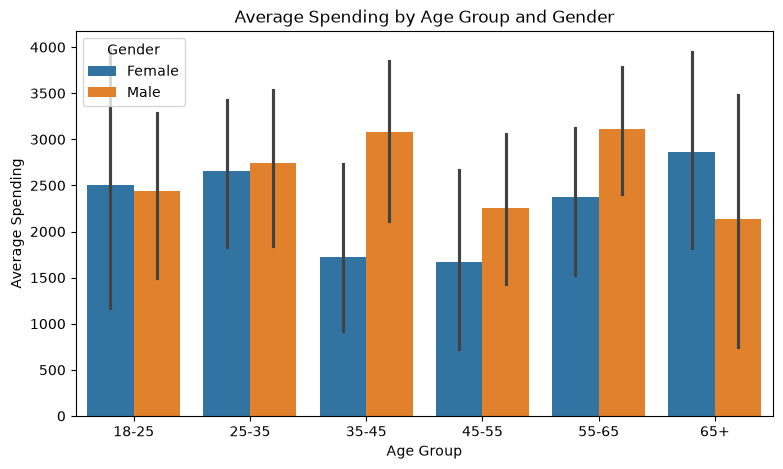

In [57]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=customer,
    x="AgeGroup",
    y="TotalAmountSpent",
    hue="Gender",
    estimator="mean"
)

plt.title("Average Spending by Age Group and Gender")
plt.xlabel("Age Group")
plt.ylabel("Average Spending")

plt.legend(title="Gender")

plt.show()

# Total Purchase Amount by location.

In [38]:
locationwise_purchase = customer.groupby('Location')['TotalAmountSpent'].sum().sort_values(ascending=False)

print(locationwise_purchase)

Location
Houston        80502.02
Phoenix        59964.31
Chicago        46500.07
New York       31409.18
Los Angeles    31043.26
Name: TotalAmountSpent, dtype: float64


Insight

Highest revenue comes from Houston.

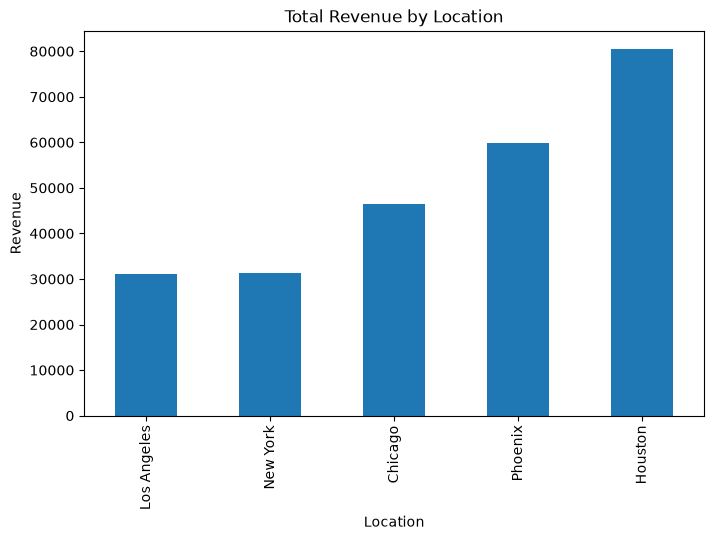

In [61]:
location_sales = customer.groupby("Location")["TotalAmountSpent"].sum().sort_values()

plt.figure(figsize=(8,5))

location_sales.plot(kind="bar")

plt.title("Total Revenue by Location")
plt.xlabel("Location")
plt.ylabel("Revenue")

plt.show()

# Churn Rate and customer loyalty based on purchase frequency.

In [ ]:
customer["LoyalCustomer"] = np.where(
    customer["TotalPurchases"] >= 20,
    "Yes",
    "No"
)

loyal = customer["LoyalCustomer"].value_counts(normalize=True)*100

print(loyal)

LoyalCustomer
No     58.0
Yes    42.0
Name: proportion, dtype: float64


Insight

42% customers are loyal.

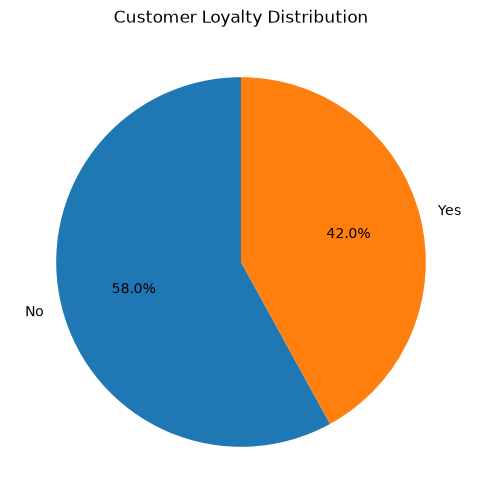

In [62]:
loyality = customer["LoyalCustomer"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(
    loyality,
    labels=loyality.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Customer Loyalty Distribution")

plt.show()

# Create personalized offers for the most valuable customers.

In [48]:
top_customers = customer[["CustomerID","TotalAmountSpent"]].sort_values(by='TotalAmountSpent',ascending=False).head(10)

print(top_customers[["CustomerID","TotalAmountSpent"]])

    CustomerID  TotalAmountSpent
97          98           4966.48
38          39           4947.37
44          45           4880.54
42          43           4835.52
40          41           4785.73
78          79           4766.31
63          64           4532.50
33          34           4467.34
87          88           4380.05
23          24           4302.12


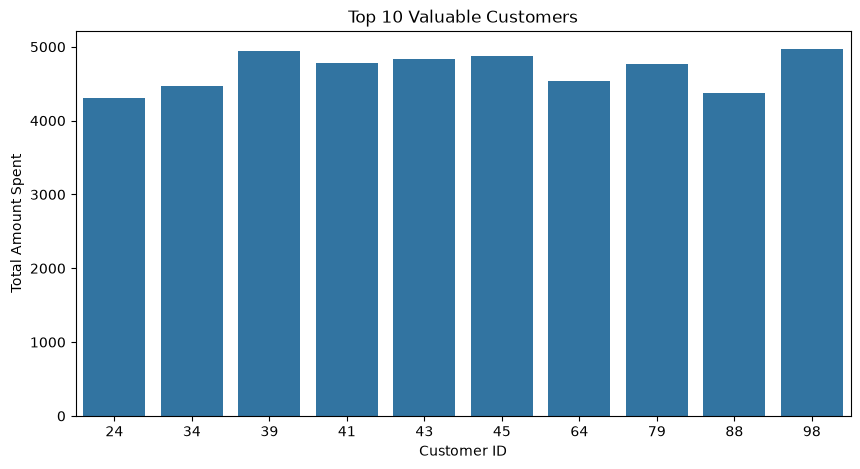

In [64]:
top_customers = customer[["CustomerID","TotalAmountSpent"]].sort_values(by='TotalAmountSpent',ascending=False).head(10)

plt.figure(figsize=(10,5))

sns.barplot(
    data=top_customers,
    x="CustomerID",
    y="TotalAmountSpent"
)

plt.title("Top 10 Valuable Customers")
plt.xlabel("Customer ID")
plt.ylabel("Total Amount Spent")

plt.show()

# Identify geographic locations with high-value customers to focus marketing efforts.

In [49]:
locationwise_purchase

Location
Houston        80502.02
Phoenix        59964.31
Chicago        46500.07
New York       31409.18
Los Angeles    31043.26
Name: TotalAmountSpent, dtype: float64

Insight:

- Houston has the highest total purchase amount, followed by Phoenix and Chicago.
- These locations contain the highest-value customers and contribute the most revenue.
- Focus marketing campaigns, premium product launches, and loyalty programs in Houston and Phoenix to maximize return on investment.

# Target specific age or gender groups with tailored campaigns based on their spending habits.

In [54]:
customer.groupby('AgeGroup')['TotalAmountSpent'].mean().sort_values(ascending=False)

AgeGroup
55-65    2866.600476
25-35    2702.492632
65+      2618.925833
18-25    2470.107143
35-45    2282.241765
45-55    1945.067647
Name: TotalAmountSpent, dtype: float64

In [52]:
customer.groupby('Gender')['TotalAmountSpent'].mean().sort_values(ascending=False)

Gender
Male      2725.1748
Female    2263.2020
Name: TotalAmountSpent, dtype: float64

Insight:

- Male customers aged 55-65 have the highest average spending and represent the most profitable customer segment.
- Female customers make purchases more frequently but spend less per transaction.